In [271]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "1")
import sys, json, math, csv
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import cv2, hydra, trimesh
import nvdiffrast.torch as dr
from PIL import Image
from hydra import compose, initialize_config_dir
from pytorch3d.transforms import so3_exp_map

DEVICE = torch.device("cuda:0")
assert torch.cuda.is_available(), "nvdiffrast richiede CUDA"
print("GPU:", torch.cuda.get_device_name(0))

GPU: NVIDIA RTX A6000


In [272]:
PROJECT_ROOT = Path('/home/riccardop02/JEPA')
DATASET_ROOT = Path('/data/riccardop02/datasets/lmo')
SPLIT = 'test'
MODELS_DIR = DATASET_ROOT / 'models'
ASSETS_DIR = DATASET_ROOT / 'assets3d'
ASSET_SUBDIR = '3DEmbedd_v3'
SCENE_ID, IMAGE_ID, GT_INDEX = 2, 65, 4
CHECKPOINT = Path('/experiments/riccardop02/outputs/2026-10-08 --DINOV3/07-00-35/checkpoints/best.pt')
CONFIG_DIR = PROJECT_ROOT / 'configs'
OUTPUT_DIR = Path('/experiments/riccardop02/Inference/landscape_comparison')
CROP_RATIO = 1.2
IMG_SIZE, PATCH = 256, 16
MICROBATCH_RENDER = 4
MICROBATCH_PREDICTOR = 16
AMP = True
ROT_DEGREES = np.linspace(-15, 15, 200)
TRANS_MM = np.linspace(-15, 15, 600)
ROT_MAP_EXTENT_DEG = 20.0
ROT_MAP_GRID = 30
PLOT_2D = True

sys.path.insert(0, str(PROJECT_ROOT))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert DATASET_ROOT.is_dir(), DATASET_ROOT
assert MODELS_DIR.is_dir(), MODELS_DIR
assert ASSETS_DIR.is_dir(), ASSETS_DIR
print('Dataset:', DATASET_ROOT, '| output:', OUTPUT_DIR)

Dataset: /data/riccardop02/datasets/lmo | output: /experiments/riccardop02/Inference/landscape_comparison


In [273]:
class NvRenderer:
    """Identical rasterizer pathway to baseline, black background, AA, vertex colors/UV textures."""
    def __init__(self,models_dir,device,size=256,near=1.,far=100000.,allow_vertex_colors=True):
        self.models_dir=Path(models_dir);self.device=torch.device(device)
        self.size=size;self.near=float(near);self.far=float(far)
        self.allow_vertex_colors=allow_vertex_colors
        self.ctx=dr.RasterizeCudaContext(device=self.device);self.cache={}
    def _load(self,obj_id):
        if obj_id in self.cache:return self.cache[obj_id]
        path=self.models_dir/f'obj_{obj_id:06d}.ply'
        if not path.is_file():raise FileNotFoundError(path)
        mesh=trimesh.load(str(path),force='mesh',process=False)
        if not isinstance(mesh,trimesh.Trimesh):raise ValueError(f'Not a triangular mesh: {path}')
        verts=np.asarray(mesh.vertices,dtype=np.float32)
        faces=np.asarray(mesh.faces,dtype=np.int32)
        if len(faces)==0:raise ValueError(f'No triangles: {path}')
        data={'vertices':torch.as_tensor(verts,device=self.device),
              'faces':torch.as_tensor(faces,device=self.device)}
        vis=mesh.visual;uv=getattr(vis,'uv',None);material=getattr(vis,'material',None)
        tex_img=getattr(material,'image',None) if material is not None else None
        if uv is not None and tex_img is not None:
            uv=np.asarray(uv,dtype=np.float32)
            if uv.shape!=(len(verts),2):raise ValueError(f'Unsupported UV: {path} {uv.shape}')
            tex=np.asarray(tex_img.convert('RGB') if isinstance(tex_img,Image.Image)
                           else Image.fromarray(np.asarray(tex_img)).convert('RGB'),dtype=np.float32)/255.
            data.update(mode='texture',uv=torch.as_tensor(uv,device=self.device),
                        tex=torch.as_tensor(tex,device=self.device).contiguous())
        elif self.allow_vertex_colors and getattr(vis,'kind',None)=='vertex':
            rgba=np.asarray(vis.vertex_colors)
            data.update(mode='vertex',colors=torch.tensor(rgba[:,:3].astype(np.float32)/255.,device=self.device))
        else:raise ValueError(f'Mesh {path} has no usable texture or vertex colors')
        self.cache[obj_id]=data
        print(f'Loaded {path.name}: {len(verts)} vertices, {len(faces)} faces, mode={data["mode"]}',flush=True)
        return data
    def render(self,obj_id,R,t,K):
        mesh=self._load(int(obj_id));v=mesh['vertices'];B=R.shape[0]
        vc=torch.einsum('bij,vj->bvi',R.float(),v)+t.float()[:,None,:]
        X,Y,Z=vc.unbind(-1)
        fx,fy=K[:,0,0,None],K[:,1,1,None]
        cx,cy=K[:,0,2,None],K[:,1,2,None]
        W=H=self.size
        xclip=2*(fx*X+cx*Z)/W-Z
        yclip=Z-2*(fy*Y+cy*Z)/H
        zclip=((self.far+self.near)/(self.far-self.near))*Z-(2*self.far*self.near)/(self.far-self.near)
        pos=torch.stack([xclip,yclip,zclip,Z],dim=-1).contiguous()
        rast,_=dr.rasterize(self.ctx,pos,mesh['faces'],resolution=[H,W],grad_db=False)
        if mesh['mode']=='texture':
            uv,_=dr.interpolate(mesh['uv'][None].expand(B,-1,-1).contiguous(),rast,mesh['faces'])
            uv=torch.stack([uv[...,0],1-uv[...,1]],dim=-1)
            rgb=dr.texture(mesh['tex'][None].expand(B,-1,-1,-1).contiguous(),uv,
                           filter_mode='linear',boundary_mode='clamp')
        else:
            rgb,_=dr.interpolate(mesh['colors'][None].expand(B,-1,-1).contiguous(),rast,mesh['faces'])
        rgb=rgb*(rast[...,3:4]>0).to(rgb.dtype)
        rgb=dr.antialias(rgb.contiguous(),rast,pos,mesh['faces'])
        return rgb.flip(1).clamp(0.,1.).permute(0,3,1,2).contiguous()

In [274]:
with initialize_config_dir(version_base=None, config_dir=str(CONFIG_DIR)):
    cfg = compose(config_name='config')
encoder = hydra.utils.instantiate(cfg.encoder2d).to(DEVICE)
encoder3d = hydra.utils.instantiate(cfg.encoder3d, in_dim=encoder.output_dim[-1]).to(DEVICE)
predictor = hydra.utils.instantiate(cfg.Predictor, context_dim=encoder3d.output_dim[0][-1], output_dim=encoder.output_dim[-1]).to(DEVICE)
try:
    ckpt=torch.load(CHECKPOINT,map_location='cpu',weights_only=True)
except Exception:
    ckpt=torch.load(CHECKPOINT,map_location='cpu',weights_only=False)
for key, module in [('encoder2d',encoder),('encoder3d',encoder3d),('predictor',predictor)]:
    module.load_state_dict(ckpt['models'][key],strict=True)
    module.eval()
    for p in module.parameters():p.requires_grad_(False)
assert IMG_SIZE//PATCH==16 and encoder.output_dim[-1]==1024, 'Controllare configurazione 256/16 e dimensione feature'
MEAN=torch.tensor([.485,.456,.406],device=DEVICE).view(1,3,1,1)
STD=torch.tensor([.229,.224,.225],device=DEVICE).view(1,3,1,1)
renderer=NvRenderer(str(MODELS_DIR),DEVICE,size=IMG_SIZE)
print('Checkpoint epoch:',ckpt.get('epoch'),'Encoder:',type(encoder).__name__)

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

DINOv3: facebook/dinov3-vitl16-pretrain-lvd1689m, layers=[18], token=PatchToken, normalize=True, freeze=True, image_size=256
Checkpoint epoch: 67 Encoder: DINOv3


lmo scene=2 image=65 GT-index=4 obj=9 | crop=(498, 213, 578, 293) | tGT(mm)=[354.64   7.97 964.42]


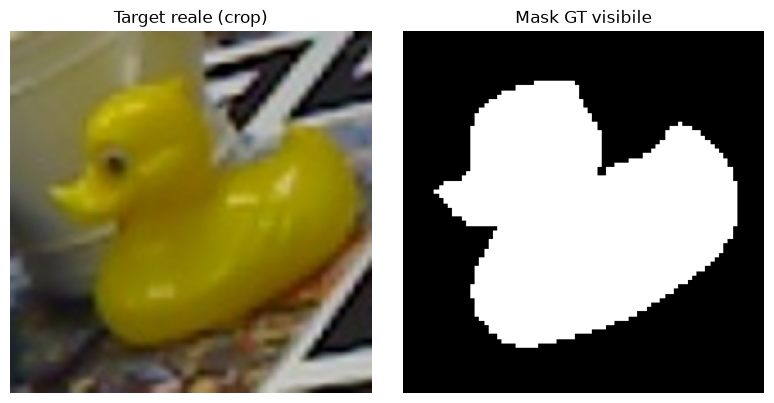

In [275]:
scene_dir = DATASET_ROOT / SPLIT / f"{SCENE_ID:06d}"
with open(scene_dir / "scene_gt.json") as f: gt_all = json.load(f)
with open(scene_dir / "scene_camera.json") as f: cam_all = json.load(f)
entries = gt_all[str(IMAGE_ID)]
assert 0 <= GT_INDEX < len(entries), f"GT_INDEX valido: 0..{len(entries)-1}"
gt = entries[GT_INDEX]
OBJ_ID = int(gt["obj_id"])
R_GT = np.array(gt["cam_R_m2c"], dtype=np.float32).reshape(3,3)
t_GT = np.array(gt["cam_t_m2c"], dtype=np.float32).reshape(3)
K_orig = np.array(cam_all[str(IMAGE_ID)]["cam_K"], dtype=np.float32).reshape(3,3)
mask_path = scene_dir / "mask_visib" / f"{IMAGE_ID:06d}_{GT_INDEX:06d}.png"
assert mask_path.exists(), f"Maschera assente: {mask_path}"
rgb_path = scene_dir / "rgb" / f"{IMAGE_ID:06d}.png"
if not rgb_path.exists(): rgb_path = rgb_path.with_suffix(".jpg")
assert rgb_path.exists(), rgb_path
rgb = np.asarray(Image.open(rgb_path).convert("RGB"))
mask = np.asarray(Image.open(mask_path).convert("L")) > 0
ys,xs=np.where(mask)
assert len(xs)>0, "Maschera visibile vuota"
cx,cy=(xs.min()+xs.max())/2,(ys.min()+ys.max())/2
half=max(xs.max()-xs.min(), ys.max()-ys.min())*CROP_RATIO/2
box=(round(cx-half),round(cy-half),round(cx+half),round(cy+half))
assert box[2]>box[0] and box[3]>box[1]
rgb_crop = np.array(Image.fromarray(rgb).crop(box).resize((IMG_SIZE,IMG_SIZE), Image.Resampling.BICUBIC))
mask_crop = np.array(Image.fromarray(mask.astype(np.uint8)*255).crop(box).resize((IMG_SIZE,IMG_SIZE), Image.Resampling.NEAREST))/255.0
sx,sy=IMG_SIZE/(box[2]-box[0]),IMG_SIZE/(box[3]-box[1])
K_crop=K_orig.copy()
K_crop[0,0]*=sx; K_crop[1,1]*=sy
K_crop[0,2]=(K_orig[0,2]-box[0])*sx
K_crop[1,2]=(K_orig[1,2]-box[1])*sy
K_t=torch.from_numpy(K_crop).to(DEVICE).float()
R_t=torch.from_numpy(R_GT).to(DEVICE).float()
t_t=torch.from_numpy(t_GT).to(DEVICE).float()
img_t=torch.from_numpy(rgb_crop.copy()).permute(2,0,1)[None].float().to(DEVICE)/255
mask_t=torch.from_numpy(mask_crop.copy())[None,None].float().to(DEVICE)
weights=F.avg_pool2d(mask_t,PATCH).flatten(1)
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
    target=encoder((img_t-MEAN)/STD).float()
assert target.ndim==3 and target.shape[1]==(IMG_SIZE//PATCH)**2, target.shape
print(f"{DATASET_ROOT.name} scene={SCENE_ID} image={IMAGE_ID} GT-index={GT_INDEX} obj={OBJ_ID} | crop={box} | tGT(mm)={t_GT.round(2)}")
fig,ax=plt.subplots(1,2,figsize=(8,4));ax[0].imshow(rgb_crop);ax[0].set_title("Target reale (crop)");ax[1].imshow(mask_crop,cmap="gray");ax[1].set_title("Mask GT visibile")
for a in ax:a.axis('off')
plt.tight_layout();plt.show()

In [276]:
asset_path = ASSETS_DIR / f'obj_{OBJ_ID:06d}' / ASSET_SUBDIR
assert asset_path.is_dir(), f'Asset PoseJEPA non trovato: {asset_path}'
def load_asset(name):
    return torch.from_numpy(np.load(asset_path / f'{name}.npy')).to(DEVICE)
with torch.no_grad():
    ctx_features, ctx_centers = encoder3d.extractFeatures(
        load_asset('view_feats').float()[None],
        load_asset('view_dirs').float()[None],
        load_asset('mask').bool()[None],
        load_asset('points').float()[None]
    )
centroid=load_asset('centroid').float().reshape(1,3)
scale=load_asset('scale').float().reshape(1)
assert float(scale[0])>0
print('Asset:',asset_path,'context:',tuple(ctx_features.shape),'scale:',float(scale[0]))

Asset: /data/riccardop02/datasets/lmo/assets3d/obj_000009/3DEmbedd_v3 context: (1, 512, 768) scale: 55.98994064331055


Loaded obj_000009.ply: 7912 vertices, 15820 faces, mode=vertex
E_GT: {'nvdiffrast': 0.021146563813090324, 'PoseJEPA': 0.018595801666378975}


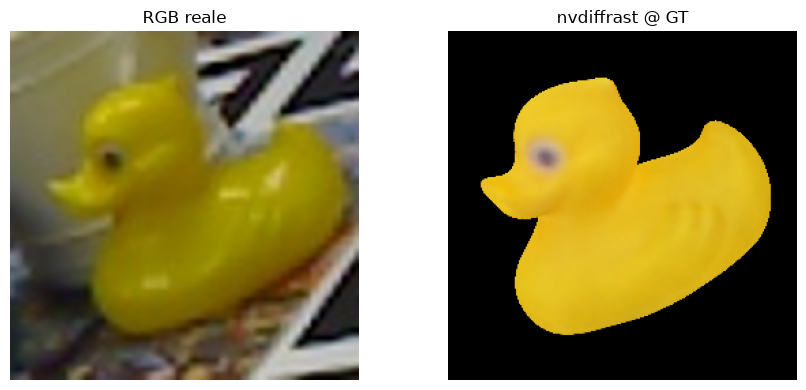

In [277]:
@torch.no_grad()
def make_rays(K,R,t,centroid,scale,grid_size=16,patch_size=16):
    B=R.shape[0]
    yy,xx=torch.meshgrid(torch.arange(grid_size,device=DEVICE,dtype=torch.float32),torch.arange(grid_size,device=DEVICE,dtype=torch.float32),indexing='ij')
    uv1=torch.stack([xx*patch_size+patch_size/2,yy*patch_size+patch_size/2,torch.ones_like(xx)],dim=-1).reshape(1,-1,3).expand(B,-1,-1)
    dc=torch.bmm(uv1,torch.linalg.inv(K).transpose(1,2))
    RT=R.transpose(1,2)
    dirs=F.normalize(torch.bmm(dc,RT.transpose(1,2)),p=2,dim=-1)
    tn=(t+(R@centroid.expand(B,-1)[...,None]).squeeze(-1))/scale.expand(B,1)
    O=-(RT@tn[...,None]).squeeze(-1)
    moments=torch.cross(O[:,None,:].expand_as(dirs),dirs,dim=-1)
    return dirs,moments

@torch.no_grad()
def energy_both(R_array,t_array,return_render=False):
    RR=torch.as_tensor(np.asarray(R_array),device=DEVICE,dtype=torch.float32).reshape(-1,3,3)
    tt=torch.as_tensor(np.asarray(t_array),device=DEVICE,dtype=torch.float32).reshape(-1,3)
    assert len(RR)==len(tt)
    results={};example=None
    for method in ('nvdiffrast','PoseJEPA'):
        size=MICROBATCH_RENDER if method=='nvdiffrast' else MICROBATCH_PREDICTOR
        vals=[]
        for lo in range(0,len(RR),size):
            hi=min(lo+size,len(RR)); B=hi-lo
            KK=K_t[None].expand(B,-1,-1)
            if method=='nvdiffrast':
                rgb_render=renderer.render(OBJ_ID,RR[lo:hi],tt[lo:hi],KK)
                if return_render and example is None:
                    example=rgb_render[0].permute(1,2,0).cpu().numpy()
                with torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
                    features=encoder((rgb_render-MEAN)/STD).float()
            else:
                dirs,moments=make_rays(KK,RR[lo:hi],tt[lo:hi],centroid,scale)
                with torch.autocast('cuda',dtype=torch.float16,enabled=AMP):
                    features=predictor(ray_dirs=dirs,ray_moments=moments,
                        context_features=ctx_features.expand(B,-1,-1),context_centers=ctx_centers.expand(B,-1,-1)).float()
            err=(features-target.expand(B,-1,-1)).abs().mean(-1)
            vals.append(((err*weights).sum(-1)/weights.sum(-1).clamp(min=1.)).cpu().numpy())
        results[method]=np.concatenate(vals)
    return (results,example) if return_render else results

E_GT, render_GT=energy_both(R_GT[None],t_GT[None],return_render=True)
print('E_GT:',{k:float(v[0]) for k,v in E_GT.items()})
fig,ax=plt.subplots(1,2,figsize=(9,4))
ax[0].imshow(rgb_crop);ax[0].set_title('RGB reale')
ax[1].imshow(render_GT);ax[1].set_title('nvdiffrast @ GT')
for a in ax:a.axis('off')
plt.tight_layout();plt.savefig(OUTPUT_DIR/'target_vs_render_GT.png',dpi=160);plt.show()

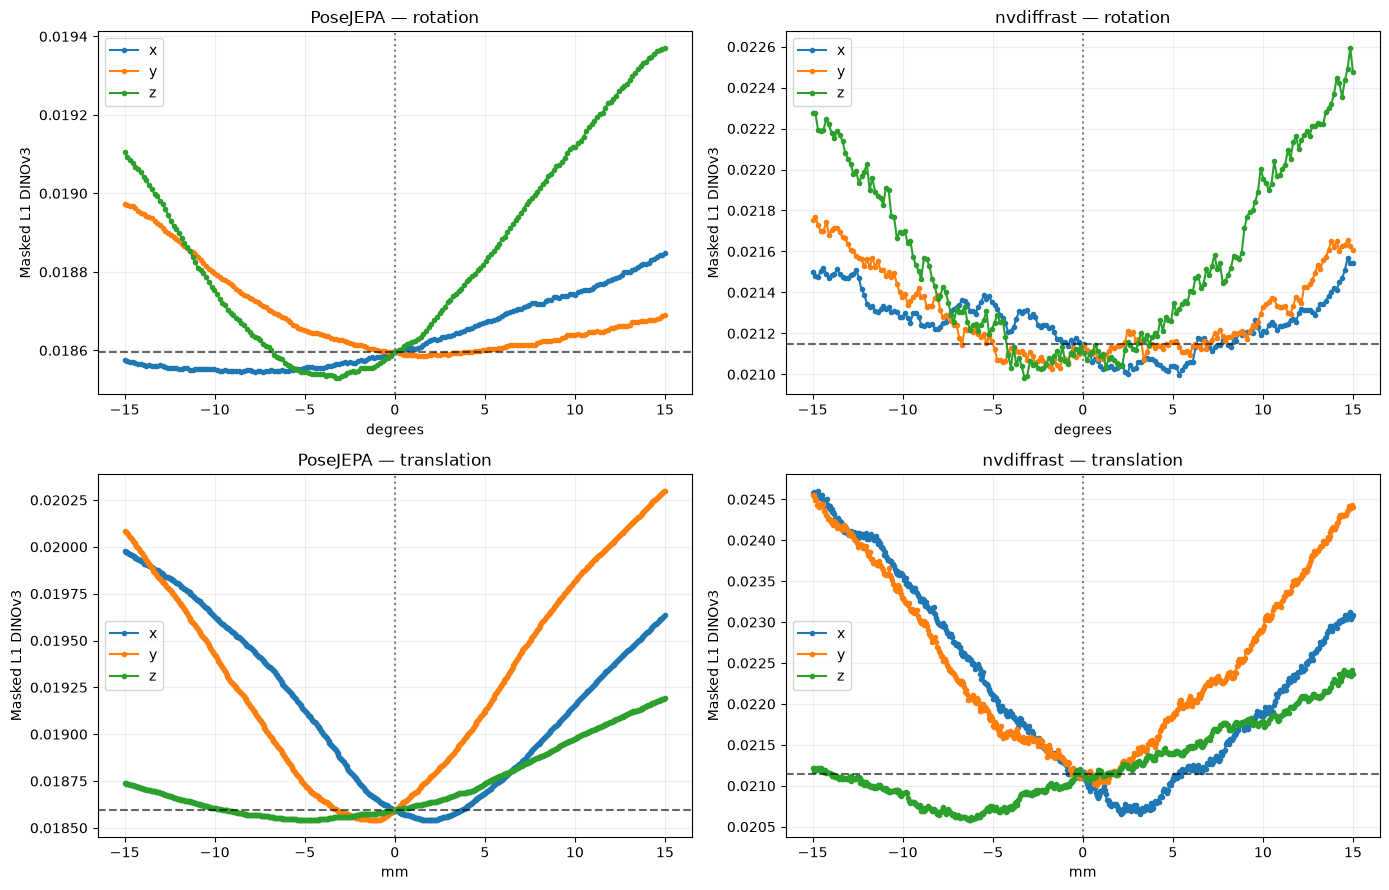

In [278]:
def rotation_grid(axis,angles_deg):
    w=np.zeros((len(angles_deg),3),dtype=np.float32)
    w[:,axis]=np.deg2rad(angles_deg)
    with torch.no_grad():dR=so3_exp_map(torch.from_numpy(w).to(DEVICE)).cpu().numpy()
    return dR@R_GT[None]

curves={method:{'rotation':{},'translation':{}} for method in ('nvdiffrast','PoseJEPA')}
for axis,name in enumerate('xyz'):
    rot=energy_both(rotation_grid(axis,ROT_DEGREES),np.repeat(t_GT[None],len(ROT_DEGREES),axis=0))
    ts=np.repeat(t_GT[None],len(TRANS_MM),axis=0);ts[:,axis]+=TRANS_MM
    trans=energy_both(np.repeat(R_GT[None],len(TRANS_MM),axis=0),ts)
    for method in curves:
        curves[method]['rotation'][name]=rot[method]
        curves[method]['translation'][name]=trans[method]

fig,axs=plt.subplots(2,2,figsize=(14,9))
for row,kind,values in [(0,'rotation',ROT_DEGREES),(1,'translation',TRANS_MM)]:
    for col,method in enumerate(('PoseJEPA','nvdiffrast')):
        ax=axs[row,col]
        for axis in 'xyz':ax.plot(values,curves[method][kind][axis],marker='.',label=axis)
        ax.axvline(0,ls=':',c='gray');ax.axhline(E_GT[method][0],ls='--',c='black',alpha=.6)
        ax.set_title(f'{method} — {kind}');ax.set_xlabel('degrees' if row==0 else 'mm')
        ax.set_ylabel('Masked L1 DINOv3');ax.grid(alpha=.2);ax.legend()
plt.tight_layout();plt.savefig(OUTPUT_DIR/'comparison_1D.png',dpi=180);plt.show()
with open(OUTPUT_DIR/'comparison_1D.csv','w',newline='') as f:
    writer=csv.writer(f);writer.writerow(['method','type','axis','offset','energy','energy_minus_gt'])
    for method in curves:
        for kind,coords in [('rotation',ROT_DEGREES),('translation',TRANS_MM)]:
            for axis in 'xyz':
                for x,y in zip(coords,curves[method][kind][axis]):
                    writer.writerow([method,kind,axis,float(x),float(y),float(y-E_GT[method][0])])

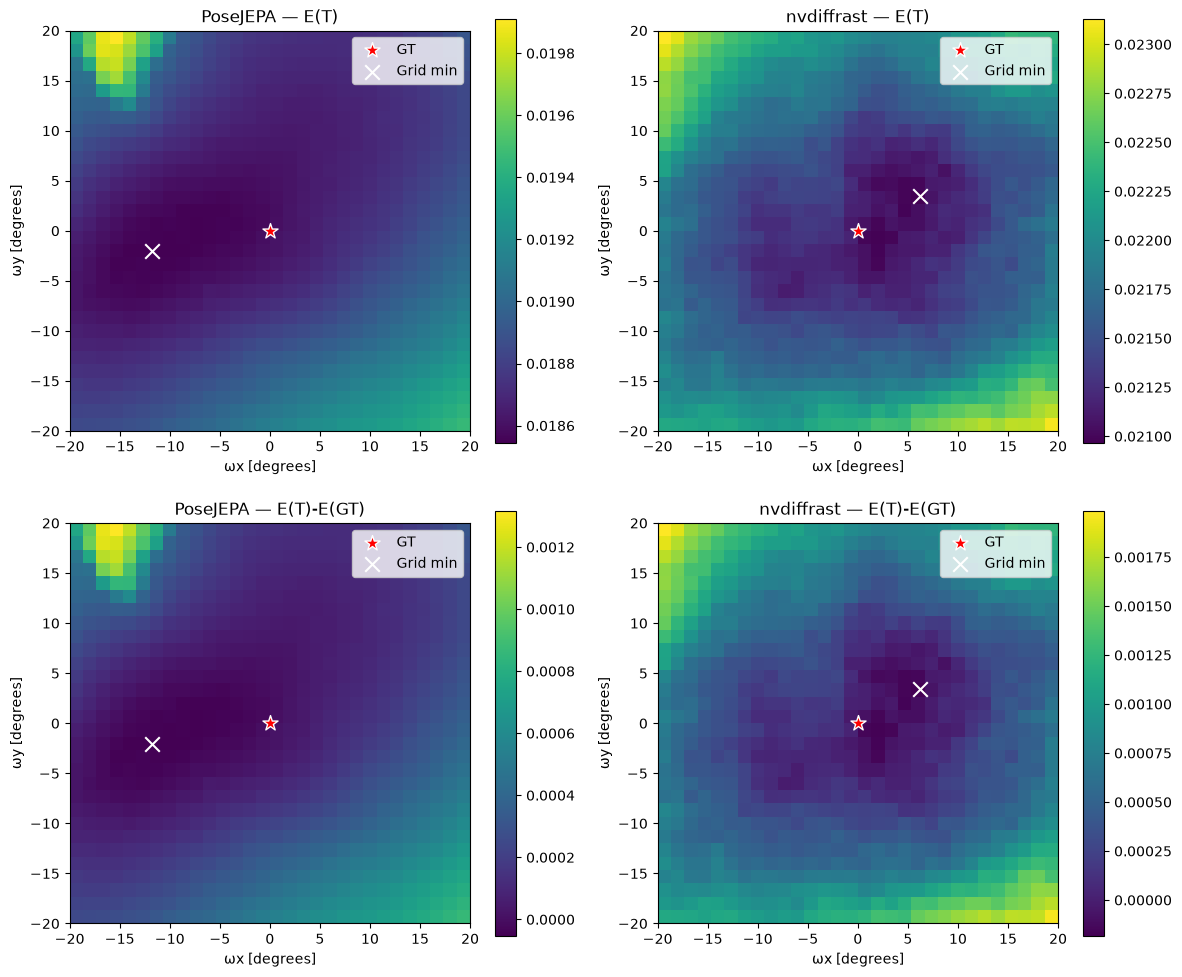

nvdiffrast sampled minimum: 0.020965463 at degrees 6.206896551724139 3.448275862068968
PoseJEPA sampled minimum: 0.018543854 at degrees -11.724137931034482 -2.0689655172413772


: 

In [ ]:
if PLOT_2D:
    coords=np.linspace(-ROT_MAP_EXTENT_DEG,ROT_MAP_EXTENT_DEG,ROT_MAP_GRID)
    U,V=np.meshgrid(coords,coords,indexing='xy')
    w=np.zeros((U.size,3),dtype=np.float32)
    w[:,0]=np.deg2rad(U.ravel());w[:,1]=np.deg2rad(V.ravel())
    with torch.no_grad():dR=so3_exp_map(torch.from_numpy(w).to(DEVICE)).cpu().numpy()
    Rs=dR@R_GT[None];ts=np.repeat(t_GT[None],len(Rs),axis=0)
    maps={k:v.reshape(U.shape) for k,v in energy_both(Rs,ts).items()}
    fig,axs=plt.subplots(2,2,figsize=(12,10))
    for col,method in enumerate(('PoseJEPA','nvdiffrast')):
        for row,z in [(0,maps[method]),(1,maps[method]-E_GT[method][0])]:
            ax=axs[row,col]
            im=ax.imshow(z,origin='lower',extent=[coords[0],coords[-1],coords[0],coords[-1]],aspect='equal',cmap='viridis')
            iy,ix=np.unravel_index(np.argmin(z),z.shape)
            ax.scatter([0],[0],marker='*',s=130,c='red',edgecolors='white',label='GT')
            ax.scatter([coords[ix]],[coords[iy]],marker='x',s=110,c='white',label='Grid min')
            ax.set_title(f'{method} — '+('E(T)' if row==0 else 'E(T)-E(GT)'))
            ax.set_xlabel('ωx [degrees]');ax.set_ylabel('ωy [degrees]');ax.legend()
            fig.colorbar(im,ax=ax)
    plt.tight_layout();plt.savefig(OUTPUT_DIR/'comparison_rotation_2D.png',dpi=180);plt.show()
    np.savez_compressed(OUTPUT_DIR/'comparison_rotation_2D.npz',axis_deg=coords,posejepa=maps['PoseJEPA'],nvdiffrast=maps['nvdiffrast'],E_GT_posejepa=float(E_GT['PoseJEPA'][0]),E_GT_nvdiffrast=float(E_GT['nvdiffrast'][0]))
    for method in maps:
        iy,ix=np.unravel_index(maps[method].argmin(),maps[method].shape)
        print(method,'sampled minimum:',maps[method][iy,ix],'at degrees',coords[ix],coords[iy])